# 20 — Response matrix and split-half reliability

**Verdict.** 46 of 90 cytokines have split-half reliability r ≥ 0.5 (Donors 1–6 vs 7–12); 44 do not. All 44 low-r cytokines sit at 0.84–1.13× the well-level null (none above 1.5×, so none is "donor-variable" at any sensible cut-off): they are **"no detectable response"**, not "donors disagree". Against the naive random-split PBS null, 35 of the 44 would have looked like responders (>2×), so the random null is wrong here. Four cell types (HSPC, ILC, Plasmablast, pDC) are dropped because ≥ 1 cytokine has < 20 cells or no donor passing; response vectors are 14 cell types × 2,000 genes = 28,000. Caveat: r ≥ 0.5 does not prove a response: 32 of the 46 reliable cytokines (e.g. EGF, Decorin, Leptin, IGF-1, r ≈ 0.5) are also < 1.5× the well null, so the whole-vector L2 test is blunt and a shared well/plate-layout effect could contribute to reliability. The user brief later mentions "40 reliable responders"; this run gives 46 at r ≥ 0.5.


CPU only. Source: full `pbmc_parse.h5ad` (9.7 M cells, 12 donors, 90 cytokines + PBS, 2,000 HVGs, raw counts — see DATA.md).

**Method / choices**
* Values are log1p(CP10k) with CP10k taken over the 2,000 HVGs in X (library = X row sum), the same convention as notebook 07. `scripts/20_pseudobulk.py` streams X once (39 s) and caches per-group sums: (donor, cytokine, cell type, `bc1_well`) and a seeded random 50/50 split of PBS cells.
* Delta(donor, cytokine, cell type) = mean over cytokine cells − mean over *that donor's* PBS cells of the same cell type; both sides need ≥ 20 cells. Deltas are averaged over the donors that pass.
* Response vector of a cytokine = concatenation (cell types × 2,000 genes) over cell types that have a delta for **every** cytokine.
* Well null: each cytokine × donor lives in one barcoding well, PBS spans 6. Null = one PBS well vs the other PBS wells of the same donor (same cell type, ≥ 20 cells each side). Random-split null = random PBS halves (the naive one).

In [1]:
import numpy as np, pandas as pd, anndata as ad, glob, scipy.sparse as sp
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
MIN_N=20; Z=np.load("../data/pseudobulk_log1p_cp10k.npz", allow_pickle=True)
genes=Z["genes"]; G=len(genes)
kA=pd.DataFrame([k.split("|") for k in Z["keysA"]],columns=["donor","cyt","ct","well"]); kA["n"]=Z["nA"]
SA=Z["sumA"]
f=glob.glob("/users/scratch1/pavelabramau/data_pavel/cellflow/hf_cache/hub/datasets--theislab--cellflow-datasets/snapshots/*/pbmc_parse.h5ad")[0]
obs=ad.read_h5ad(f,backed="r").obs[["cytokine","cytokine_family"]].astype(str).drop_duplicates()
fam=obs.set_index("cytokine")["cytokine_family"]
DONORS=[f"Donor{i}" for i in range(1,13)]
print(kA.shape, kA.cyt.nunique()-1, "cytokines;", kA.ct.nunique(),"cell types")

(20524, 5) 90 cytokines; 18 cell types


## 1. Donor × cytokine × cell-type deltas

In [2]:
# PBS pooled per (donor, ct)
P=kA[kA.cyt=="PBS"]
pbs_sum=pd.DataFrame(SA[P.index]).groupby([P.donor.values,P.ct.values]).sum()
pbs_n=P.groupby(["donor","ct"]).n.sum()
pbs_mean=pbs_sum.div(pbs_n.reindex(pbs_sum.index).values,axis=0)
rows=[];D={}
for i,r in kA[kA.cyt!="PBS"].iterrows():
    key=(r.donor,r.ct)
    if r.n>=MIN_N and key in pbs_n.index and pbs_n[key]>=MIN_N:
        D[(r.cyt,r.donor,r.ct)]=SA[i]/r.n-pbs_mean.loc[key].values
cyts=sorted(kA.cyt.unique()); cyts.remove("PBS"); cts=sorted(kA.ct.unique())
avail=pd.DataFrame(0,index=cyts,columns=cts)
for (c,d,t) in D: avail.loc[c,t]+=1
print("deltas:",len(D)," of possible",len(cyts)*12*len(cts))
cts_all=[t for t in cts if (avail[t]>0).all()]; dropped=[t for t in cts if t not in cts_all]
print("cell types kept (%d):"%len(cts_all),cts_all)
print("DROPPED (%d):"%len(dropped),dropped)
pd.DataFrame({"cytokines with >=1 donor":(avail>0).sum(),"min donors per cytokine":avail.min(),"median donors":avail.median()}).T

deltas: 15204  of possible 19440
cell types kept (14): ['B Intermediate/Memory', 'B Naive', 'CD14 Mono', 'CD16 Mono', 'CD4 Memory', 'CD4 Naive', 'CD8 Memory', 'CD8 Naive', 'MAIT', 'NK', 'NK CD56bright', 'NKT', 'Treg', 'cDC']
DROPPED (4): ['HSPC', 'ILC', 'Plasmablast', 'pDC']


,B Intermediate/Memory,B Naive,CD14 Mono,CD16 Mono,CD4 Memory,CD4 Naive,CD8 Memory,CD8 Naive,HSPC,ILC,MAIT,NK,NK CD56bright,NKT,Plasmablast,Treg,cDC,pDC
cytokines with >=1 donor,90.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,87.0,43.0,90.0,90.0,90.0,90.0,15.0,90.0,90.0,89.0
min donors per cytokine,12.0,12.0,12.0,9.0,12.0,10.0,12.0,10.0,0.0,0.0,11.0,12.0,12.0,2.0,0.0,11.0,8.0,0.0
median donors,12.0,12.0,12.0,11.0,12.0,12.0,12.0,12.0,3.0,0.0,12.0,12.0,12.0,10.0,0.0,12.0,11.0,2.0


In [3]:
# why were they dropped? which cytokines lack them
for t in dropped:
    miss=[c for c in cyts if avail.loc[c,t]==0]
    print(f"{t}: missing for {len(miss)}/90 cytokines", miss[:8],"..." if len(miss)>8 else "")
print(); print("PBS cells per ct (all donors):"); print(pbs_n.groupby("ct").sum().loc[dropped])

HSPC: missing for 3/90 cytokines ['BAFF', 'GITRL', 'TL1A'] 
ILC: missing for 47/90 cytokines ['APRIL', 'BAFF', 'CD27L', 'CD40L', 'FGF-beta', 'FasL', 'GITRL', 'IFN-beta'] ...
Plasmablast: missing for 75/90 cytokines ['ADSF', 'APRIL', 'BAFF', 'C3a', 'C5a', 'CD30L', 'CD40L', 'Decorin'] ...
pDC: missing for 1/90 cytokines ['IL-32-beta'] 

PBS cells per ct (all donors):
ct
HSPC           1035.0
ILC             510.0
Plasmablast     403.0
pDC            1273.0
Name: n, dtype: float64


In [4]:
def resp_vec(c, donors, tlist):
    out=[]
    for t in tlist:
        ds=[D[(c,d,t)] for d in donors if (c,d,t) in D]
        if not ds: return None
        out.append(np.mean(ds,axis=0))
    return np.concatenate(out)
R=np.vstack([resp_vec(c,DONORS,cts_all) for c in cyts])
print("response matrix",R.shape)

response matrix (90, 28000)


## 2. Split-half reliability (Donors 1–6 vs Donors 7–12)

In [5]:
H1,H2=DONORS[:6],DONORS[6:]
rel=[]
for c in cyts:
    ok=[t for t in cts_all if any((c,d,t) in D for d in H1) and any((c,d,t) in D for d in H2)]
    a=resp_vec(c,H1,ok); b=resp_vec(c,H2,ok)
    r=np.corrcoef(a,b)[0,1] if a is not None else np.nan
    rel.append({"cytokine":c,"family":fam.get(c),"r_split_half":r,"n_ct_in_both_halves":len(ok),
                "n_donors_min_over_ct":avail.loc[c,cts_all].min(),"n_donors_median_over_ct":avail.loc[c,cts_all].median()})
rel=pd.DataFrame(rel).set_index("cytokine")
rel["reliable"]=rel.r_split_half>=0.5
print("r>=0.5:",rel.reliable.sum(),"of",len(rel))
print(rel[rel.reliable].sort_values("r_split_half",ascending=False)[["family","r_split_half"]].round(3).to_string())
print("\ncytokines with a ct missing in one half:",(rel.n_ct_in_both_halves<len(cts_all)).sum())

r>=0.5: 46 of 90
                                   family  r_split_half
cytokine                                               
IFN-beta                       Interferon         0.947
IL-15           Common γ chain/IL-13/TSLP         0.923
IL-7            Common γ chain/IL-13/TSLP         0.921
IL-4            Common γ chain/IL-13/TSLP         0.920
IL-2            Common γ chain/IL-13/TSLP         0.916
CD40L                                 TNF         0.915
IFN-omega                      Interferon         0.913
IFN-gamma                      Interferon         0.897
IL-32-beta   Interleukin - non-classified         0.896
IL-1-beta                            IL-1         0.878
GM-CSF                     Common β chain         0.873
IL-12                          IL-6/IL-12         0.870
IL-21           Common γ chain/IL-13/TSLP         0.864
IL-10                               IL-10         0.850
TSLP            Common γ chain/IL-13/TSLP         0.841
TL1A                           

## 3. Low-r cytokines vs response magnitude relative to the null

In [6]:
# magnitude = L2 norm of delta over the 2000 HVGs, per (donor,ct); null = PBS well vs other PBS wells (same donor, ct).
wn=[]
for (d,t),g in P.groupby(["donor","ct"]):
    for i in g.index:
        n_w=kA.n[i]; rest=g.index.difference([i]); n_r=kA.n[rest].sum()
        if n_w>=MIN_N and n_r>=MIN_N:
            wn.append({"donor":d,"ct":t,"null":"well","norm":np.linalg.norm(SA[i]/n_w-SA[rest].sum(0)/n_r),"n_a":n_w,"n_b":n_r})
# random-split null from group B
kB=pd.DataFrame([k.split("|") for k in Z["keysB"]],columns=["donor","ct","half"]); kB["n"]=Z["nB"]; SB=Z["sumB"]
for (d,t),g in kB[kB.donor!=""].groupby(["donor","ct"]):
    if len(g)==2 and (g.n>=MIN_N).all():
        i0,i1=g.index
        wn.append({"donor":d,"ct":t,"null":"random","norm":np.linalg.norm(SB[i0]/g.n[i0]-SB[i1]/g.n[i1]),"n_a":g.n[i0],"n_b":g.n[i1]})
wn=pd.DataFrame(wn); wn=wn[wn.ct.isin(cts_all)]
null_med=wn.groupby(["null","ct"]).norm.median().unstack(0)   # per-ct null norm (median over donors/wells)
print(wn.groupby("null").norm.describe().round(3))
print("\nnull norm by cell type (median):"); print(null_med.round(3).T.to_string())

        count   mean    std    min    25%    50%    75%     max
null                                                           
random  168.0  1.876  1.499  0.392  0.972  1.424  2.265   9.830
well    982.0  3.439  1.351  1.006  2.495  3.178  4.090  10.675

null norm by cell type (median):
ct      B Intermediate/Memory  B Naive  CD14 Mono  CD16 Mono  CD4 Memory  CD4 Naive  CD8 Memory  CD8 Naive   MAIT     NK  NK CD56bright    NKT   Treg    cDC
null                                                                                                                                                        
random                  1.814    1.364      0.592      1.527       0.587      0.707       1.078      1.326  1.539  1.267          2.899  2.333  2.401  2.794
well                    3.352    2.921      3.273      3.517       2.197      2.171       2.531      2.845  3.174  2.897          4.559  3.510  4.265  4.709


In [7]:
# observed magnitude per cytokine = median over (donor,ct) of ||delta|| / median null norm of that ct; both nulls
obsm=[]
for (c,d,t),v in D.items():
    if t in cts_all: obsm.append({"cytokine":c,"donor":d,"ct":t,"norm":np.linalg.norm(v)})
obsm=pd.DataFrame(obsm)
for nl in ["well","random"]: obsm["ratio_"+nl]=obsm.norm/obsm.ct.map(null_med[nl])
mag=obsm.groupby("cytokine")[["ratio_well","ratio_random"]].median()
mag["frac_donorct_above_2x_well"]=obsm.assign(a=obsm.ratio_well>2).groupby("cytokine").a.mean()
rel=rel.join(mag)
rel["n_donors_total"]=[len({d for (cc,d,t) in D if cc==c}) for c in rel.index]
THR=2.0
def cls(r):
    if r.r_split_half>=0.5: return "reliable (r>=0.5)"
    return "low r, response > %gx well null (donor-variable)"%THR if r.ratio_well>THR else "low r, response <= %gx well null (no detectable response)"%THR
rel["category"]=rel.apply(cls,axis=1)
rel["category_random_null"]=rel.apply(lambda r:("reliable (r>=0.5)" if r.r_split_half>=0.5 else ("low r, > %gx random null"%THR if r.ratio_random>THR else "low r, <= %gx random null"%THR)),axis=1)
print(rel.category.value_counts().to_string()); print(); print(rel.category_random_null.value_counts().to_string())
print("\ncross-tab  well-null category (rows) vs random-null category (cols):")
print(pd.crosstab(rel.category,rel.category_random_null))

category
reliable (r>=0.5)                                           46
low r, response <= 2x well null (no detectable response)    44

category_random_null
reliable (r>=0.5)           46
low r, > 2x random null     35
low r, <= 2x random null     9

cross-tab  well-null category (rows) vs random-null category (cols):
category_random_null                                low r, <= 2x random null  \
category                                                                       
low r, response <= 2x well null (no detectable ...                         9   
reliable (r>=0.5)                                                          0   

category_random_null                                low r, > 2x random null  \
category                                                                      
low r, response <= 2x well null (no detectable ...                       35   
reliable (r>=0.5)                                                         0   

category_random_null                      

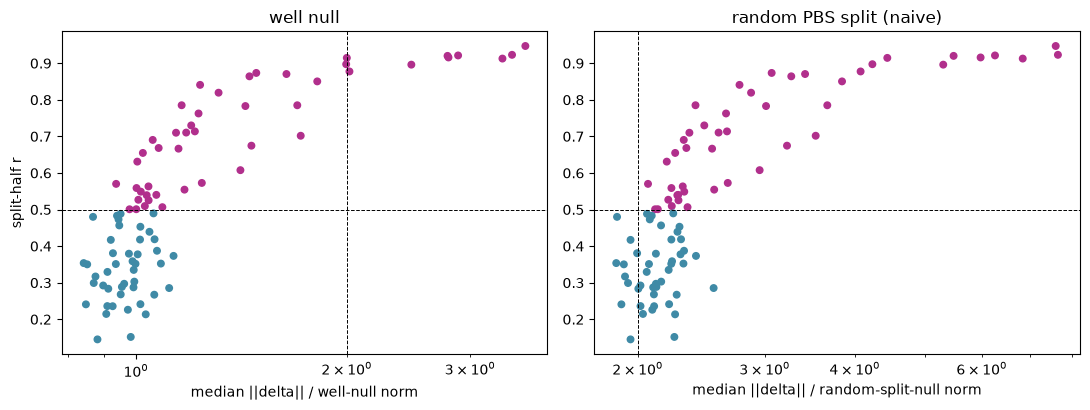

,family,r_split_half,ratio_well,ratio_random,n_donors_total,category
cytokine,,,,,,
SCF,Growth factor,0.145,0.881,1.954,12,"low r, response <= 2x well null (no detectable..."
IL-36Ra,IL-1,0.152,0.983,2.248,12,"low r, response <= 2x well null (no detectable..."
IL-17E,IL-17,0.214,1.032,2.253,12,"low r, response <= 2x well null (no detectable..."
GDNF,Other,0.215,0.907,2.033,12,"low r, response <= 2x well null (no detectable..."
LIF,IL-6/IL-12,0.226,0.974,2.095,12,"low r, response <= 2x well null (no detectable..."
...,...,...,...,...,...,...
IL-2,Common γ chain/IL-13/TSLP,0.916,2.793,5.976,12,reliable (r>=0.5)
IL-4,Common γ chain/IL-13/TSLP,0.920,2.785,5.482,12,reliable (r>=0.5)
IL-7,Common γ chain/IL-13/TSLP,0.921,2.883,6.257,12,reliable (r>=0.5)


In [8]:
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
col=rel.reliable.map({True:"#B12F8C",False:"#3F8AA6"})
ax[0].scatter(rel.ratio_well,rel.r_split_half,c=col,s=22); ax[0].axhline(.5,ls="--",c="k",lw=.7); ax[0].axvline(THR,ls="--",c="k",lw=.7)
ax[0].set_xscale("log"); ax[0].set_xlabel("median ||delta|| / well-null norm"); ax[0].set_ylabel("split-half r"); ax[0].set_title("well null")
ax[1].scatter(rel.ratio_random,rel.r_split_half,c=col,s=22); ax[1].axhline(.5,ls="--",c="k",lw=.7); ax[1].axvline(THR,ls="--",c="k",lw=.7)
ax[1].set_xscale("log"); ax[1].set_xlabel("median ||delta|| / random-split-null norm"); ax[1].set_title("random PBS split (naive)")
plt.tight_layout(); plt.savefig("../models/20_reliability_vs_magnitude.png",dpi=130); plt.show()
pd.set_option("display.width",200)
rel.sort_values("r_split_half")[["family","r_split_half","ratio_well","ratio_random","n_donors_total","category"]].round(3)

## 4. D_response and cache

In [9]:
def cosdist(M): 
    Mn=M/np.linalg.norm(M,axis=1,keepdims=True); return np.clip(1-Mn@Mn.T,0,2)
D_all=cosdist(R); np.fill_diagonal(D_all,0)
relmask=rel.reliable.values; D_rel=D_all[np.ix_(relmask,relmask)]
print("D_all",D_all.shape,"D_reliable",D_rel.shape, "median off-diag all/rel:",np.median(D_all[np.triu_indices(90,1)]).round(3),np.median(D_rel[np.triu_indices(relmask.sum(),1)]).round(3))
var=pd.DataFrame({"cell_type":np.repeat(cts_all,G),"gene":np.tile(genes,len(cts_all))}); var.index=var.cell_type+"|"+var.gene
A=ad.AnnData(X=R.astype(np.float32),obs=rel.copy(),var=var)
A.obs["family"]=A.obs["family"].astype(str); A.obs["category"]=A.obs["category"].astype(str); A.obs["category_random_null"]=A.obs["category_random_null"].astype(str)
A.obsp["D_response_all"]=D_all
A.uns["D_response_reliable"]=D_rel; A.uns["reliable_cytokines"]=list(rel.index[relmask])
A.uns["cell_types_kept"]=cts_all; A.uns["cell_types_dropped"]=dropped
A.uns["null_norms"]=null_med.reset_index().rename(columns={"index":"ct"}).astype(str).to_dict("list")
A.uns["params"]={"min_cells":MIN_N,"normalisation":"log1p(CP10k over 2000 HVGs)","split_half":"Donor1-6 vs Donor7-12","reliable_threshold":0.5,"magnitude_threshold":THR}
A.write_h5ad("../data/response_matrix.h5ad"); rel.to_csv("../data/reliability.csv")
print("saved"); np.save("../data/D_response_all.npy",D_all); np.save("../data/D_response_reliable.npy",D_rel)

D_all (90, 90) D_reliable (46, 46) median off-diag all/rel: 0.927 0.961
saved
